In [17]:

import importlib.util
import subprocess
import sys
if importlib.util.find_spec("fairlearn") is None:
    print("Installing Fairlearn. Enable Kaggle Internet if this fails.")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "fairlearn>=0.10,<1"])
else:
    print("Fairlearn is available; installation skipped.")

Fairlearn is available; installation skipped.


In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from fairlearn.metrics import (
    MetricFrame, selection_rate, true_positive_rate, false_positive_rate,
    demographic_parity_difference, demographic_parity_ratio,
    equalized_odds_difference
)
from fairlearn.postprocessing import ThresholdOptimizer

SEED = 42
np.random.seed(SEED)
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("setc_outputs")
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
print("Output folder:", OUTPUT_DIR.resolve())

Output folder: /content/setc_outputs


In [9]:

SEARCH_ROOTS = [Path("/kaggle/input"), Path("/mnt/data"), Path(".")]
ADULT_COLUMNS = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]

def normalize_name(name):
    return str(name).strip().lower().replace("-", "_").replace(" ", "_").replace(".", "_")

def adult_candidate_files():
    result = []
    for root in SEARCH_ROOTS:
        if root.exists():
            for pattern in ("**/*.csv", "**/adult.data", "**/adult.test"):
                result.extend(root.glob(pattern))
    result = list(dict.fromkeys(x.resolve() for x in result if x.is_file()))
    return sorted(result, key=lambda x: ("adult" not in x.name.lower(), "adult" not in str(x).lower(), len(str(x))))

def read_adult_csv(path):

    data = pd.read_csv(path, skipinitialspace=True, na_values=["?", " ?", "", "NA"])
    data.columns = [normalize_name(c) for c in data.columns]
    data = data.rename(columns={"class": "income", "salary": "income", "target": "income", "label": "income"})
    if "income" not in data.columns or "sex" not in data.columns:
        data = pd.read_csv(path, header=None, names=ADULT_COLUMNS,
                           comment="|", skipinitialspace=True,
                           na_values=["?", " ?", "", "NA"])
    if not {"income", "sex"}.issubset(data.columns):
        raise ValueError("CSV lacks required columns 'income' and 'sex'.")
    if len(data.columns) != 15:
        raise ValueError(f"Expected 15 Adult attributes, found {len(data.columns)}.")
    return data


ADULT_CSV = None
if ADULT_CSV:
    df_raw = read_adult_csv(Path(ADULT_CSV))
    selected_path = Path(ADULT_CSV)
else:
    selected_path, df_raw = None, None
    for candidate in adult_candidate_files():
        try:
            attempted = read_adult_csv(candidate)
            if len(attempted) >= 1000:
                selected_path, df_raw = candidate, attempted
                break
        except (ValueError, pd.errors.ParserError, UnicodeError):
            continue
    if df_raw is None:
        raise FileNotFoundError(
            "Adult Income CSV not found. Kaggle → Add Input → attach the UCI Adult Income "
            "dataset (adult.csv / adult.data), then Run All. "
            "Or set ADULT_CSV to its absolute CSV path."
        )
print("Dataset:", selected_path)
print("Raw shape:", df_raw.shape)
display(df_raw.head(3))

Dataset: /content/sample_data/mnist_test.csv
Raw shape: (10000, 15)


,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,84,185,159,151,60,36,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,222,254,254,254,254,241,198,198,198,198,198,198,198,198,170,52,0,0,0,0,0,0,0,0,0,0,0,0,67,114,72,114,163,227,254,225,254,254,254,250,229,254,254,140,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,17,66,14,67,67,67,59,21,236,254,106,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,83,253,209,18,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,22,233,255,83,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,129,254,238,44,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,59,249,254,62,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,133,254,187,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9,205,248,58,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,126,254,182,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,75,251,240,57,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,19,221,254,166,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,203,254,219,35,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,38,254,254,77,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,31,224,254,115,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,133,254,254,52,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,61,242,254,254,52,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,121,254,254,219,40,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,121,254,207,18,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,116,125,171,255,255,150,93,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,169,253,253,253,253,253,253,218,30,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,169,253,253,253,213,142,176,253,253,122,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,52,250,253,210,32,12,0,6,206,253,140,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,77,251,210,25,0,0,0,122,248,253,65,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,31,18,0,0,0,0,209,253,253,65,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,117,247,253,198,10,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,76,247,253,231,63,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,128,253,253,144,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,176,246,253,159,12,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,25,234,253,233,35,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,198,253,253,141,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,78,248,253,189,12,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,19,200,253,253,141,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,134,253,253,173,12,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,248,253,253,25,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,248,253,253,43,20,20,20,20,5,0,5,20,20,37,150,150,150,147,10,0

In [10]:

import pandas as pd
import urllib.request

clean = df_raw.copy()

if clean is None or "income" not in clean.columns or not clean["income"].astype(str).str.contains("50K").any():
    print("Correct Adult dataset not found. Downloading directly from UCI Repository...")
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
    ADULT_COLUMNS = [
        "age", "workclass", "fnlwgt", "education", "education_num",
        "marital_status", "occupation", "relationship", "race", "sex",
        "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
    ]
    df_raw = pd.read_csv(url, header=None, names=ADULT_COLUMNS, skipinitialspace=True, na_values=["?"])
    clean = df_raw.copy()

# Remove unknown/missing records, standardize labels and sex values
for column in clean.select_dtypes(include=["object", "string"]).columns:
    clean[column] = clean[column].astype("string").str.strip()
    clean[column] = clean[column].replace({"?": pd.NA, "": pd.NA, "nan": pd.NA})
clean = clean.dropna().reset_index(drop=True)


income_text = clean["income"].astype(str).str.strip().str.rstrip(".").str.replace(" ", "", regex=False)
valid_income = income_text.isin(["<=50K", ">50K"])
if not valid_income.all():
    raise ValueError("Unexpected income labels: " + str(income_text[~valid_income].unique().tolist()[:8]))
y = (income_text == ">50K").astype(int)

sex = clean["sex"].astype(str).str.strip().str.title()
if not set(sex.unique()).issubset({"Male", "Female"}):
    raise ValueError("Unexpected sex groups: " + str(sex.unique().tolist()))


X = clean.drop(columns=["income", "sex"])
X = X.loc[:, ~X.columns.str.startswith("unnamed")]
for col in X.columns:
    if col in ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]:
        X[col] = pd.to_numeric(X[col], errors="coerce")
X = X.dropna(axis=0) if X.isna().any().any() else X
if len(X) != len(y):
    kept = X.index
    y, sex = y.loc[kept], sex.loc[kept]

X_train, X_test, y_train, y_test, sex_train, sex_test = train_test_split(
    X, y, sex, test_size=0.30, stratify=y, random_state=SEED
)
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:  # scikit-learn < 1.2
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=True)
preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), num_cols),
    ("categorical", encoder, cat_cols)
])
model = Pipeline([
    ("preprocessing", preprocess),
    ("logistic_regression", LogisticRegression(max_iter=1000, random_state=SEED))
])
model.fit(X_train, y_train)
y_baseline = model.predict(X_test)
print(f"Clean samples: {len(X):,} | Train: {len(X_train):,} | Test: {len(X_test):,}")
print("Class counts:", y.value_counts().to_dict())
print("Model features:", len(X.columns), "| 'sex' included:", "sex" in X.columns)
print(f"Baseline overall accuracy: {accuracy_score(y_test, y_baseline):.4f}")

Correct Adult dataset not found. Downloading directly from UCI Repository...
Clean samples: 30,162 | Train: 21,113 | Test: 9,049
Class counts: {0: 22654, 1: 7508}
Model features: 13 | 'sex' included: False
Baseline overall accuracy: 0.8462


In [11]:

METRICS = {
    "accuracy": accuracy_score,
    "selection_rate": selection_rate,
    "TPR": true_positive_rate,
    "FPR": false_positive_rate,
}

def audit_predictions(name, predictions):
    frame = MetricFrame(
        metrics=METRICS, y_true=y_test, y_pred=predictions,
        sensitive_features=sex_test
    )
    group = frame.by_group.reindex(["Male", "Female"])
    overall_accuracy = accuracy_score(y_test, predictions)
    dp_diff = demographic_parity_difference(y_test, predictions, sensitive_features=sex_test)
    dp_ratio = demographic_parity_ratio(y_test, predictions, sensitive_features=sex_test)
    eo_diff = equalized_odds_difference(y_test, predictions, sensitive_features=sex_test)
    summary = {
        "model": name,
        "accuracy": overall_accuracy,
        "selection_male": float(group.loc["Male", "selection_rate"]),
        "selection_female": float(group.loc["Female", "selection_rate"]),
        "dp_difference": dp_diff,
        "dp_ratio": dp_ratio,
        "eo_difference": eo_diff,
    }
    print(f"\n{name} | Accuracy: {overall_accuracy:.4f}")
    display(group.round(4))
    print(f"DP difference: {dp_diff:.4f} | DP ratio (disparate impact): {dp_ratio:.4f}")
    print(f"Equalized odds difference: {eo_diff:.4f}")
    return {"name": name, "by_group": group, "summary": summary, "predictions": predictions}

baseline = audit_predictions("Baseline", y_baseline)
print("Four-fifths (80%) rule:", "PASS" if baseline["summary"]["dp_ratio"] >= 0.80 else "FAIL / FLAG FOR REVIEW")
baseline["by_group"].to_csv(OUTPUT_DIR / "baseline_group_metrics.csv")


Baseline | Accuracy: 0.8462


,accuracy,selection_rate,TPR,FPR
sex,,,,
Male,0.8122,0.2590,0.6147,0.0991
Female,0.9181,0.0892,0.5303,0.0293


DP difference: 0.1698 | DP ratio (disparate impact): 0.3443
Equalized odds difference: 0.0844
Four-fifths (80%) rule: FAIL / FLAG FOR REVIEW


In [12]:
# Task 4: Demographic parity mitigation
optimizer_dp = ThresholdOptimizer(
    estimator=model, constraints="demographic_parity", prefit=True,
    predict_method="predict_proba"
)
optimizer_dp.fit(X_train, y_train, sensitive_features=sex_train)
y_dp = optimizer_dp.predict(X_test, sensitive_features=sex_test, random_state=SEED)
mitigated_dp = audit_predictions("TO: demographic_parity", y_dp)
mitigated_dp["by_group"].to_csv(OUTPUT_DIR / "demographic_parity_group_metrics.csv")


TO: demographic_parity | Accuracy: 0.8292


,accuracy,selection_rate,TPR,FPR
sex,,,,
Male,0.7974,0.1618,0.4341,0.0394
Female,0.8964,0.1632,0.7493,0.0837


DP difference: 0.0014 | DP ratio (disparate impact): 0.9915
Equalized odds difference: 0.3152


In [13]:
# Task 5: Equalized odds mitigation
optimizer_eo = ThresholdOptimizer(
    estimator=model, constraints="equalized_odds", prefit=True,
    predict_method="predict_proba"
)
optimizer_eo.fit(X_train, y_train, sensitive_features=sex_train)
y_eo = optimizer_eo.predict(X_test, sensitive_features=sex_test, random_state=SEED)
mitigated_eo = audit_predictions("TO: equalized_odds", y_eo)
mitigated_eo["by_group"].to_csv(OUTPUT_DIR / "equalized_odds_group_metrics.csv")


TO: equalized_odds | Accuracy: 0.8342


,accuracy,selection_rate,TPR,FPR
sex,,,,
Male,0.8118,0.2173,0.5470,0.0691
Female,0.8816,0.1312,0.5533,0.0739


DP difference: 0.0861 | DP ratio (disparate impact): 0.6036
Equalized odds difference: 0.0063


,accuracy,selection_male,selection_female,dp_difference,dp_ratio,eo_difference,accuracy_loss_vs_baseline
model,,,,,,,
Baseline,0.8462,0.2590,0.0892,0.1698,0.3443,0.0844,0.0000
TO: demographic_parity,0.8292,0.1618,0.1632,0.0014,0.9915,0.3152,0.0170
TO: equalized_odds,0.8342,0.2173,0.1312,0.0861,0.6036,0.0063,0.0119


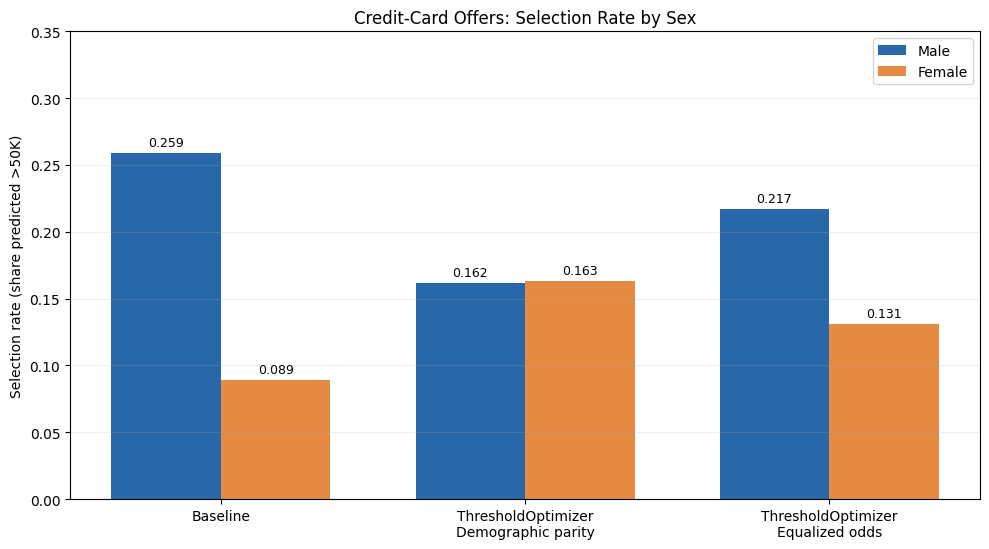

Plot saved: setc_outputs/selection_rate_by_sex.png


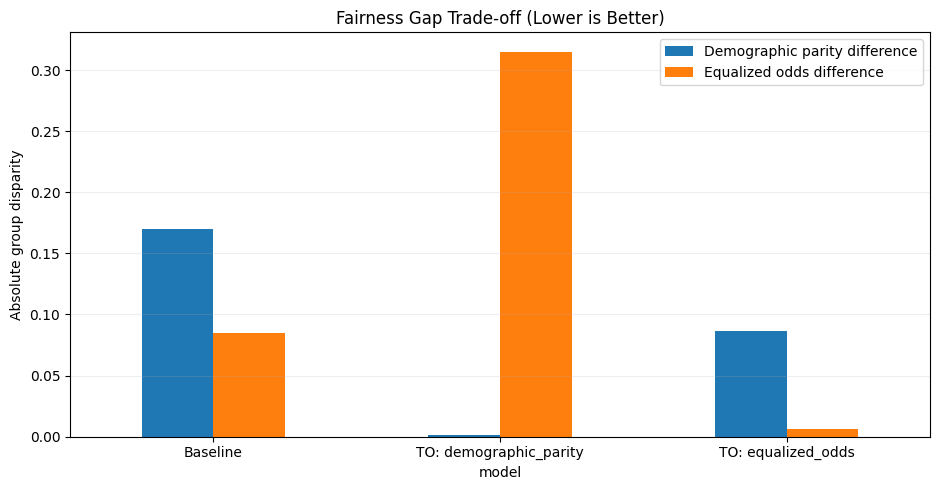

In [14]:

all_results = [baseline, mitigated_dp, mitigated_eo]
comparison = pd.DataFrame([r["summary"] for r in all_results]).set_index("model")
comparison["accuracy_loss_vs_baseline"] = baseline["summary"]["accuracy"] - comparison["accuracy"]
display(comparison.round(4))
comparison.to_csv(OUTPUT_DIR / "accuracy_fairness_comparison.csv")

plot_data = comparison[["selection_male", "selection_female"]]
fig, ax = plt.subplots(figsize=(10, 5.6))
centers = np.arange(len(plot_data.index))
width = 0.36
ax.bar(centers-width/2, plot_data["selection_male"], width, label="Male", color="#2868a8")
ax.bar(centers+width/2, plot_data["selection_female"], width, label="Female", color="#e58a43")
ax.set_xticks(centers, ["Baseline", "ThresholdOptimizer\nDemographic parity", "ThresholdOptimizer\nEqualized odds"])
ax.set_ylabel("Selection rate (share predicted >50K)")
ax.set_title("Credit-Card Offers: Selection Rate by Sex")
ax.set_ylim(0, min(1, max(0.35, float(plot_data.max().max()) * 1.23)))
ax.grid(axis="y", alpha=0.2)
ax.legend()
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
fig.tight_layout()
plot_path = OUTPUT_DIR / "selection_rate_by_sex.png"
fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()
print("Plot saved:", plot_path)


fig, ax = plt.subplots(figsize=(9.5, 5))
comparison[["dp_difference", "eo_difference"]].rename(columns={
    "dp_difference": "Demographic parity difference",
    "eo_difference": "Equalized odds difference"
}).plot(kind="bar", ax=ax, rot=0)
ax.set_title("Fairness Gap Trade-off (Lower is Better)")
ax.set_ylabel("Absolute group disparity")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "fairness_gap_comparison.png", dpi=200, bbox_inches="tight")
plt.show()